In [ ]:
# IMPORTANT: RUN THIS CELL IN ORDER TO IMPORT YOUR KAGGLE DATA SOURCES,
# THEN FEEL FREE TO DELETE THIS CELL.
# NOTE: THIS NOTEBOOK ENVIRONMENT DIFFERS FROM KAGGLE'S PYTHON
# ENVIRONMENT SO THERE MAY BE MISSING LIBRARIES USED BY YOUR
# NOTEBOOK.
import kagglehub
bogdancretu_flower299_path = kagglehub.dataset_download('bogdancretu/flower299')

print('Data source import complete.')


Using Colab cache for faster access to the 'flower299' dataset.
Data source import complete.


In [ ]:
import numpy as np
import pandas as pd
import math

import torch
import torchvision
import torchvision.datasets
import torch.nn as nn
import torch.nn.functional as F
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, Dataset, random_split
from torchsummary import summary

from PIL import Image
import os
import matplotlib.pyplot as plt
import seaborn as sns
from math import ceil, sqrt
from tqdm.notebook import tqdm

In [ ]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
device

device(type='cuda')

## Dataset

In [ ]:
img_dir = bogdancretu_flower299_path
img_dir

'/kaggle/input/flower299'

In [ ]:
class Flower104(Dataset):
    def __init__(self, split='train', transform=None):
        self.img_dir = img_dir + '/' + split
        image_paths = [list(map(lambda name: class_name + '/' + name, os.listdir(self.img_dir + '/' + class_name))) for class_name in os.listdir(self.img_dir)]
        image_paths = sum(image_paths, [])
        self.image_paths = image_paths
        self.transform = transform

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):
        img_path = os.path.join(self.img_dir, self.image_paths[idx])
        img = Image.open(img_path).convert('RGB')
        return self.transform(img)

In [ ]:
WIDTH = 64

MEAN = [0.4475, 0.4168, 0.2963]
STD = [0.2791, 0.2415, 0.2653]

transform = transforms.Compose([
    transforms.Resize((WIDTH, WIDTH)),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

# train_ = Flower104(split='train', transform=transform)
# test_ = Flower104(split='val', transform=transform)

dataset = Flower104(split='Flowers299', transform=transform)

train_, test_ = random_split(dataset, [0.8, 0.2])

BATCH_SIZE = 16
N_CHANNELS = train_[0].size(0)
WIDTH = train_[0].size(1)

train_loader = DataLoader(train_, batch_size=BATCH_SIZE, shuffle=True, drop_last=True)
test_loader = DataLoader(test_, batch_size=BATCH_SIZE, shuffle=False, drop_last=True)

In [ ]:
train_.__len__()

92756

In [ ]:
def show_image(images: torch.Tensor, titles: list[str] = None, n_cols: int = None):
    """
    Рисует одну картинку или батч картинок из torch.Tensor.

    Args:
        images: тензор shape (C, H, W) для одной картинки
                или (B, C, H, W) для батча
        titles: список заголовков длиной B (опционально)
        n_cols: количество колонок в сетке. По умолчанию ~sqrt(B)
    """
    # Переносим на CPU и отключаем градиенты
    imgs = images.detach().cpu()

    # Если одна картинка (CHW), оборачиваем в батч
    if imgs.ndim == 3:
        imgs = imgs.unsqueeze(0)

    b = imgs.shape[0]

    # Определяем размер сетки
    if n_cols is None:
        n_cols = b
    n_rows = ceil(b / n_cols)

    fig, axes = plt.subplots(n_rows, n_cols, figsize=(3 * n_cols, 3 * n_rows))

    # Если всего одна картинка, axes не будет массивом
    if b == 1 and n_rows == 1 and n_cols == 1:
        axes = [[axes]]
    elif n_rows == 1:
        axes = [axes]
    elif n_cols == 1:
        axes = [[ax] for ax in axes]

    for idx in range(n_rows * n_cols):
        row, col = idx // n_cols, idx % n_cols
        ax = axes[row][col]

        if idx < b:
            img = imgs[idx].permute(1, 2, 0)  # CHW -> HWC

            # Grayscale
            if img.shape[2] == 1:
                img = img.squeeze(2)

            # Нормализуем в [0, 1] если нужно
            if img.max() > 1.0 or img.min() < 0.0:
                img = (img - img.min()) / (img.max() - img.min() + 1e-8)

            ax.imshow(img, cmap='bone' if img.ndim == 2 else None)

            if titles and idx < len(titles):
                ax.set_title(titles[idx], fontsize=9)
        else:
            # Пустые ячейки, если батч не заполняет сетку целиком
            pass

        ax.axis('off')

    plt.tight_layout()
    plt.show()

In [ ]:
train_[0].shape

torch.Size([3, 64, 64])

In [ ]:
cur_img = train_[0]

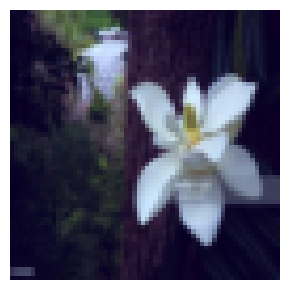

In [ ]:
show_image(cur_img)

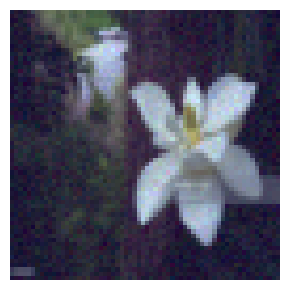

In [ ]:
to = cur_img * (torch.randn_like(cur_img) * .1 + 1)
show_image(to)

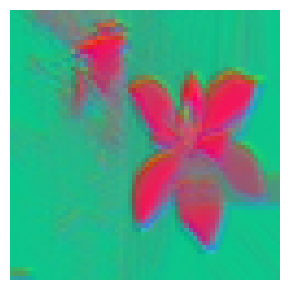

torch.Size([3, 62, 62])


In [ ]:
kernel_size = 3

weight = torch.randn(3, 3, kernel_size, kernel_size)
weight -= weight.mean()
weight /= weight.sum()
edited_img = torch.nn.functional.conv2d(cur_img, weight)
show_image(edited_img)
print(edited_img.shape)

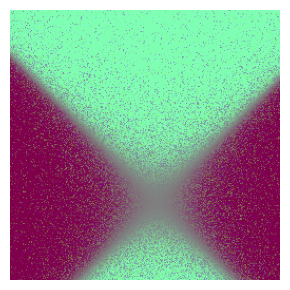

In [ ]:
width = 128
size = 5
image = torch.tensor([[[np.tanh(((i - size / 2 + j) * np.random.random() * .5 * (i - j - size / 3))) * np.tan(c ** 5) for j in np.arange(-size, size, size / width)] for i in np.arange(-size, size, size / width)] for c in range(3)], dtype=torch.float32)
show_image(image)

## Modeling

In [ ]:
class SinusoidalPosEmb(nn.Module):
    def __init__(self, dim):
        super().__init__()
        self.dim = dim

    def forward(self, x):
        device = x.device
        half_dim = self.dim // 2
        emb = math.log(10000) / (half_dim - 1)
        emb = torch.exp(torch.arange(half_dim, device=device) * -emb)
        emb = x[:, None] * emb[None, :]
        emb = torch.cat((emb.sin(), emb.cos()), dim=-1)
        return emb

class TimeEmbedding(nn.Module):
    def __init__(self, dim):
        super().__init__()
        self.sin_emb = SinusoidalPosEmb(dim)
        self.mlp = nn.Sequential(
            nn.Linear(dim, dim * 4),
            nn.SiLU(),
            nn.Linear(dim * 4, dim)
        )

    def forward(self, t):
        x = self.sin_emb(t)
        return self.mlp(x)

class DiTBlock(nn.Module):
    def __init__(self, hidden_dim, num_heads):
        super().__init__()
        self.norm1 = nn.LayerNorm(hidden_dim, elementwise_affine=False, eps=1e-6)
        self.attn = nn.MultiheadAttention(hidden_dim, num_heads, batch_first=True)
        self.norm2 = nn.LayerNorm(hidden_dim, elementwise_affine=False, eps=1e-6)

        self.mlp = nn.Sequential(
            nn.Linear(hidden_dim, hidden_dim * 4),
            nn.GELU(approximate="tanh"),
            nn.Linear(hidden_dim * 4, hidden_dim)
        )

        self.adaLN_modulation = nn.Sequential(
            nn.SiLU(),
            nn.Linear(hidden_dim, 6 * hidden_dim)
        )

    def forward(self, x, c):
        # 1. Получаем модулирующие параметры
        shift_msa, scale_msa, gate_msa, shift_mlp, scale_mlp, gate_mlp = self.adaLN_modulation(c).chunk(6, dim=-1)

        # 2. Добавляем измерение unsqueeze(1) -> размерность становится [B, 1, hidden_dim]
        shift_msa = shift_msa.unsqueeze(1)
        scale_msa = scale_msa.unsqueeze(1)
        gate_msa = gate_msa.unsqueeze(1)
        shift_mlp = shift_mlp.unsqueeze(1)
        scale_mlp = scale_mlp.unsqueeze(1)
        gate_mlp = gate_mlp.unsqueeze(1)

        # 3. Вычисления (теперь broadcasting сработает автоматически)
        x_norm1 = self.norm1(x) * (1 + scale_msa) + shift_msa
        attn_out, _ = self.attn(x_norm1, x_norm1, x_norm1)
        x = x + gate_msa * attn_out

        x_norm2 = self.norm2(x) * (1 + scale_mlp) + shift_mlp
        mlp_out = self.mlp(x_norm2)
        x = x + gate_mlp * mlp_out

        return x

class DiT(nn.Module):
    def __init__(
        self,
        img_size=32,
        patch_size=2,
        in_channels=3,
        hidden_dim=256,
        depth=6,
        num_heads=4
    ):
        super().__init__()
        self.path_size = patch_size
        self.in_channels = in_channels
        self.num_patches = (img_size // patch_size) ** 2

        self.patch_embed = nn.Conv2d(in_channels, hidden_dim, kernel_size=patch_size, stride=patch_size)
        self.pos_embed = nn.Parameter(torch.zeros(1, self.num_patches, hidden_dim))

        self.time_embed = TimeEmbedding(hidden_dim)

        self.blocks = nn.ModuleList([
            DiTBlock(hidden_dim, num_heads) for _ in range(depth)
        ])

        self.final_norm = nn.LayerNorm(hidden_dim, elementwise_affine=False, eps=1e-6)
        self.final_adaLN = nn.Sequential(
            nn.SiLU(),
            nn.Linear(hidden_dim, 2 * hidden_dim)
        )
        self.final_linear = nn.Linear(hidden_dim, patch_size * patch_size * in_channels)

    def unpatchify(self, x):
        c = self.in_channels
        p = self.path_size
        h = w = int(x.shape[1] ** 0.5)

        x = x.reshape(shape=(x.shape[0], h, w, p, p, c))
        x = torch.einsum('nhwpqc->nchpwq', x)
        imgs = x.reshape(shape=(x.shape[0], c, h * p, w * p))
        return imgs

    def forward(self, x, t=None):
        if t == None:
            t = torch.zeros(x.size(0)).to(device)
        c = self.time_embed(t.float())

        x = self.patch_embed(x).flatten(2).transpose(1, 2)
        x = x + self.pos_embed

        for block in self.blocks:
            x = block(x, c)

        shift, scale = self.final_adaLN(c).chunk(2, dim=-1)
        shift = shift.unsqueeze(1) # [B, 1, hidden_dim]
        scale = scale.unsqueeze(1) # [B, 1, hidden_dim]

        x = self.final_norm(x) * (1 + scale) + shift
        x = self.final_linear(x)

        imgs = self.unpatchify(x)
        return imgs

In [ ]:
model = DiT(img_size=WIDTH, patch_size=8, depth=4, hidden_dim=128, num_heads=8, in_channels=N_CHANNELS).to(device)
# model = nn.DataParallel(model, device_ids=[0, 1], output_device=0)

summary(model, input_size=(N_CHANNELS, WIDTH, WIDTH), batch_size=BATCH_SIZE)


----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
  SinusoidalPosEmb-1                  [16, 128]               0
            Linear-2                  [16, 512]          66,048
              SiLU-3                  [16, 512]               0
            Linear-4                  [16, 128]          65,664
     TimeEmbedding-5                  [16, 128]               0
            Conv2d-6            [16, 128, 8, 8]          24,704
              SiLU-7                  [16, 128]               0
            Linear-8                  [16, 768]          99,072
         LayerNorm-9              [16, 64, 128]               0
MultiheadAttention-10  [[-1, 64, 128], [-1, 64, 64]]               0
        LayerNorm-11              [16, 64, 128]               0
           Linear-12              [16, 64, 512]          66,048
             GELU-13              [16, 64, 512]               0
           Linear-14              

## Training

### Noising fn

In [ ]:
MAX_STEPS = 10
START = 0
END = 1

def alpha(step):
    return START + (END - START) * (step / MAX_STEPS)

def noise_strength(n_step):
    return alpha(n_step)

def add_noise(image, n_steps):
    noise = torch.rand_like(image)
    strength = noise_strength(n_steps)
    a = image * np.sqrt(strength)
    b = noise * np.sqrt(1 - strength)
    return a + b, noise

In [ ]:
next(iter(train_loader)).std(dim=(0, -1, -2))

AttributeError: 'list' object has no attribute 'std'

In [ ]:
show_image(add_noise(train_[0], torch.tensor(1))[0].squeeze())

TypeError: rand_like(): argument 'input' (position 1) must be Tensor, not tuple

In [ ]:
def add_noise_batch(images):
    """
    Быстрое добавление шума к батчу изображений

    Args:
        images: tensor формы [batch_size, channels, height, width]
        timesteps: tensor формы [batch_size] с индексами шагов (0 to MAX_STEPS-1)

    Returns:
        noisy_images: зашумленные изображения
        noise: добавленный шум (нужен для обучения)
    """
    batch_size = images.shape[0]
    device = images.device

    # Получаем alpha_bar для каждого примера в батче
    alpha_bar_t = torch.rand(batch_size, device=images.device)

    # Добавляем размерности для broadcasting
    # Форма: [batch_size, 1, 1, 1] чтобы广播到所有 пикселям
    alpha_bar_t = alpha_bar_t.view(batch_size, *([1] * (images.dim() - 1)))

    # Генерируем шум
    noise = torch.randn_like(images)

    # Применяем формулу: x_t = alpha_bar_t * x_0 + (1 - alpha_bar_t) * noise
    alpha_bar = alpha_bar_t
    one_minus_alpha_bar = 1 - alpha_bar_t

    noisy_images = alpha_bar * images + one_minus_alpha_bar * noise

    return noisy_images, alpha_bar_t.squeeze()

In [ ]:
show_image(train_[1])

AttributeError: 'tuple' object has no attribute 'detach'

In [ ]:
show_image(train_[1] * torch.tensor(STD).view(3, 1, 1) + torch.tensor(MEAN).view(3, 1, 1))

TypeError: only integer tensors of a single element can be converted to an index

In [ ]:
a = torch.zeros((64, 3, 32, 32))
a_noisy, t = add_noise_batch(a)
t.shape

torch.Size([64])

### training fn

In [ ]:
import gc

def clear_cuda():
    torch.cuda.empty_cache()
    gc.collect()

In [ ]:
def visualize_diffusion_steps(model, train_loader, device, n_steps_vis=5):
    """
    Показывает оригинал, зашумленные версии и попытки восстановления моделью.
    """
    model.eval()

    # 1. Берем одну картинку из датасета
    # Предполагаем, что train_loader возвращает (images, labels)
    data_iter = iter(train_loader)
    imgs = next(data_iter)
    original_img = imgs[0].unsqueeze(0).to(device) # (1, C, H, W)

    # 2. Выбираем шаги времени для визуализации (равномерно от шума к чистоте)
    # Например: [900, 700, 500, 300, 100] если T=1000
    timesteps = torch.linspace(MAX_STEPS - 1, 0, n_steps_vis, dtype=torch.long).to(device)

    fig, axes = plt.subplots(2, n_steps_vis + 1, figsize=(20, 8))

    # --- Верхний ряд: Оригиналы и Шум ---

    axes[0, 0].imshow(original_img[0].cpu().permute(1, 2, 0).clamp(0, 1))
    axes[0, 0].set_title("Original")
    axes[0, 0].axis('off')

    noisy_imgs = []

    for i, t in enumerate(timesteps):
        # Добавляем шум к оригиналу для конкретного шага t
        alpha_bar_t = alpha(t)
        noise = torch.randn_like(original_img)

        # Формула прямого процесса
        noisy_img = alpha_bar_t * original_img + (1 - alpha_bar_t) * noise

        noisy_imgs.append(noisy_img)

        # Отображаем зашумленную картинку
        image = noisy_img[0].cpu().permute(1, 2, 0)
        image = (image - image.min()) / (image.max() - image.min() + 1e-6)
        axes[0, i+1].imshow(image)
        axes[0, i+1].set_title(f"Noise t={t.item()}")
        axes[0, i+1].axis('off')

    # --- Нижний ряд: Восстановление моделью ---
    # Пытаемся восстановить x0 из каждого зашумленного состояния
    with torch.no_grad():
        for i, t in enumerate(timesteps):
            noisy_input = noisy_imgs[i]

            # Создаем тензор времени для модели
            t_tensor = torch.full((1,), t.item(), device=device, dtype=torch.long)

            # Предсказываем шум
            predicted_noise = model(noisy_input, t_tensor)

            # Восстанавливаем x0 по формуле: x0 = (xt - sqrt(1-a)*eps) / sqrt(a)
            alpha_bar_t = alpha(t).item()
            pred_x0 = (noisy_input - (1 - alpha_bar_t) * predicted_noise) / (alpha_bar_t + 1e-8)

            # Отображаем результат
            image = pred_x0[0].cpu().permute(1, 2, 0)
            image = (image - image.min()) / (image.max() - image.min() + 1e-8)
            axes[1, i+1].imshow(image)
            axes[1, i+1].set_title(f"Reconstructed t={t.item()}")
            axes[1, i+1].axis('off')

    # Первая ячейка нижнего ряда пустая или с подписью
    axes[1, 0].text(0.5, 0.5, "Model\nRestoration", ha='center', va='center', fontsize=12)
    axes[1, 0].axis('off')

    plt.tight_layout()
    plt.show()
    model.train()

def denoise():
    visualize_diffusion_steps(model, train_loader, device)

RuntimeError: permute(sparse_coo): number of dimensions in the tensor input does not match the length of the desired ordering of dimensions i.e. input.dim() = 4 is not equal to len(dims) = 3

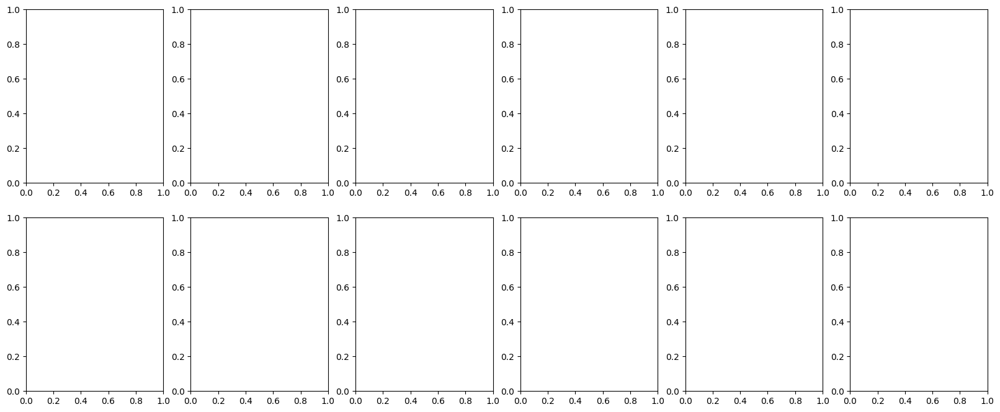

In [ ]:
denoise()

In [ ]:
from scipy.integrate import solve_ivp

@torch.no_grad()
def generation_step(img, step, n_steps, cur_model=model):
    # Функция для диффура
    @torch.no_grad()
    def func(t, y):
      img = torch.from_numpy(y).to(device).view(-1, N_CHANNELS, WIDTH, WIDTH).float()
      output = cur_model(img, torch.tensor((t,)).to(device))
      return output.flatten().cpu().numpy()

    t = step / n_steps
    dt = 1 / n_steps
    t_span = (t, t + dt)
    y0 = img.flatten().cpu().numpy()
    result = solve_ivp(func, t_span, y0, t_eval=(t + dt,), method='RK45')
    flow = torch.from_numpy(result.y).view(-1, N_CHANNELS, WIDTH, WIDTH)
    img = flow.to(device)
    return img

@torch.no_grad()
def generate(n_images, n_steps=MAX_STEPS, temp=1.0, cur_model=model, show=True):
    img = torch.randn((n_images, N_CHANNELS, WIDTH, WIDTH), device=device)
    model.eval()
    for step in range(n_steps):
        img = generation_step(img, step, n_steps, cur_model=cur_model)
    if show:
        show_image(img.cpu() * torch.tensor(STD).view(3, 1, 1) + torch.tensor(MEAN).view(3, 1, 1))
    model.train()
    return img


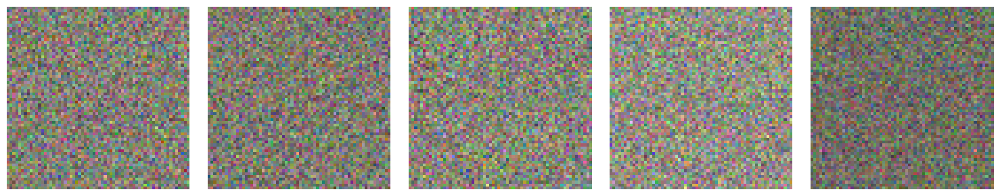

In [ ]:
img = generate(n_images=5, n_steps=1)

In [ ]:
def validate(criterion):
    model.eval()
    sum_loss = 0
    with torch.no_grad():
        for img in tqdm(test_loader, leave=False):
            img = img.to(device)
            noisy_img, t = add_noise_batch(img)
            noisy_img = noisy_img.to(device)
            t.to(device)

            predicted_noise = model(noisy_img, t)
            loss = criterion((img - noisy_img) / (1 - t).view(-1, 1, 1, 1), predicted_noise)

            sum_loss += loss.item()
    return sum_loss / test_loader.__len__()

def distil_prob(epoch, n_epochs):
    perc = epoch / n_epochs
    if perc < 0.3:
        return 0
    if perc < 0.8:
      return perc - 0.3
    return 0.5

def train(n_epochs=10, LR=1e-4, save_dir='./models/', val_steps=1, img_show_steps=1):
    criterion = nn.MSELoss()
    optimizer = torch.optim.AdamW(model.parameters(), lr=LR)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=n_epochs, eta_min=0.00005)

    model.train()

    val_losses = []
    train_losses = []

    for epoch in range(n_epochs):
        train_loss = 0
        for img in tqdm(train_loader, leave=False):
            img = img.to(device)
            noisy_img, t = add_noise_batch(img)
            noisy_img = noisy_img.to(device)
            t = t.to(device)

            predicted_noise = model(noisy_img, t)
            loss = criterion((img - noisy_img) / (1 - t).view(-1, 1, 1, 1), predicted_noise)
            train_loss += loss.item()

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

        train_loss /= train_loader.__len__()
        train_losses.append(train_loss)

        print(f'Epoch [{epoch + 1:3}/{n_epochs}] finished. Train MSE: {train_loss:.4f}', end=' | ')
        if epoch % val_steps == 0:
            val_loss = validate(criterion)
            val_losses.append(val_loss)
            print(f'Test MSE: {val_loss:.4f}')
        print()

        if epoch % img_show_steps == 0:
            img = generate(n_images=5, n_steps=1)

    print('Training completed')
    return val_losses, train_losses

  0%|          | 0/5797 [00:00<?, ?it/s]

Epoch [  1/10] finished. Train MSE: 0.8325 | 

  0%|          | 0/1449 [00:00<?, ?it/s]

Test MSE: 0.7629



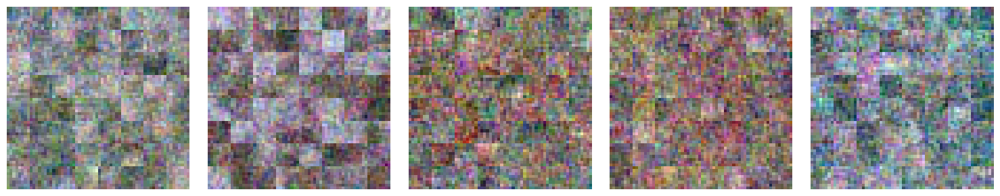

  0%|          | 0/5797 [00:00<?, ?it/s]

Epoch [  2/10] finished. Train MSE: 0.7588 | 

  0%|          | 0/1449 [00:00<?, ?it/s]

Test MSE: 0.7551



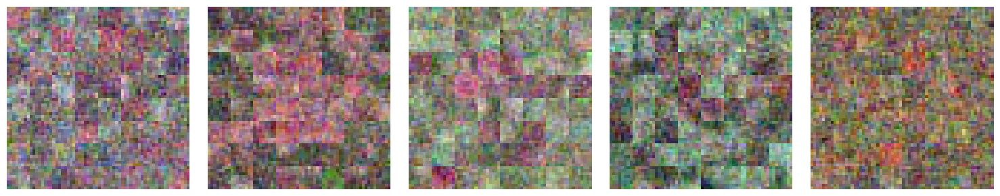

  0%|          | 0/5797 [00:00<?, ?it/s]

Epoch [  3/10] finished. Train MSE: 0.7498 | 

  0%|          | 0/1449 [00:00<?, ?it/s]

Test MSE: 0.7406



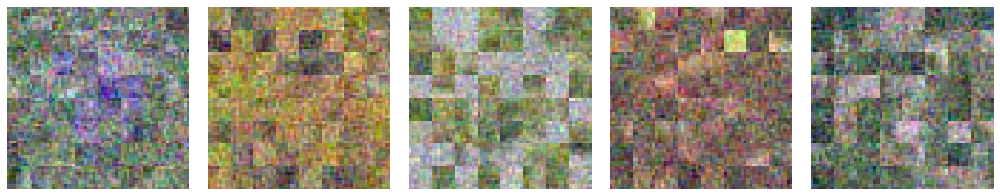

  0%|          | 0/5797 [00:00<?, ?it/s]

Epoch [  4/10] finished. Train MSE: 0.7440 | 

  0%|          | 0/1449 [00:00<?, ?it/s]

Test MSE: 0.7457



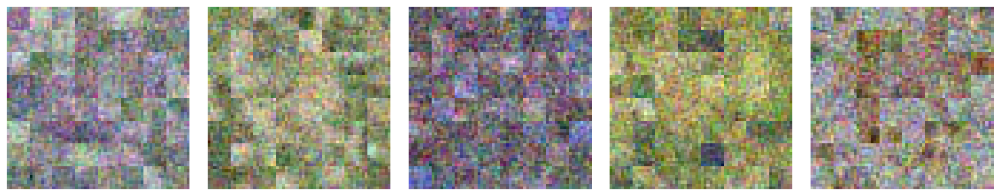

  0%|          | 0/5797 [00:00<?, ?it/s]

Epoch [  5/10] finished. Train MSE: 0.7403 | 

  0%|          | 0/1449 [00:00<?, ?it/s]

Test MSE: 0.7420



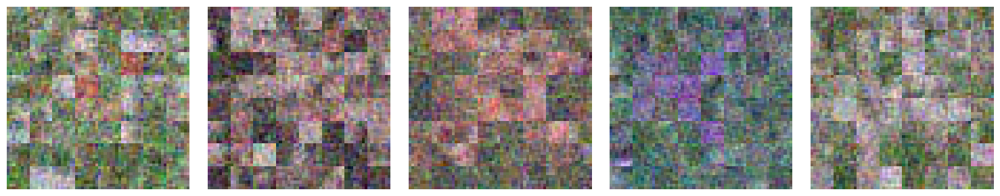

  0%|          | 0/5797 [00:00<?, ?it/s]

Epoch [  6/10] finished. Train MSE: 0.7372 | 

  0%|          | 0/1449 [00:00<?, ?it/s]

Test MSE: 0.7363



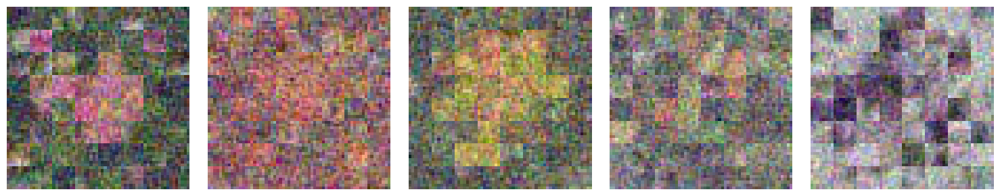

  0%|          | 0/5797 [00:00<?, ?it/s]

Epoch [  7/10] finished. Train MSE: 0.7342 | 

  0%|          | 0/1449 [00:00<?, ?it/s]

Test MSE: 0.7334



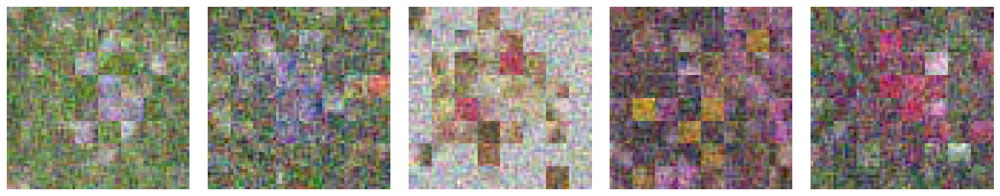

  0%|          | 0/5797 [00:00<?, ?it/s]

Epoch [  8/10] finished. Train MSE: 0.7326 | 

  0%|          | 0/1449 [00:00<?, ?it/s]

Test MSE: 0.7331



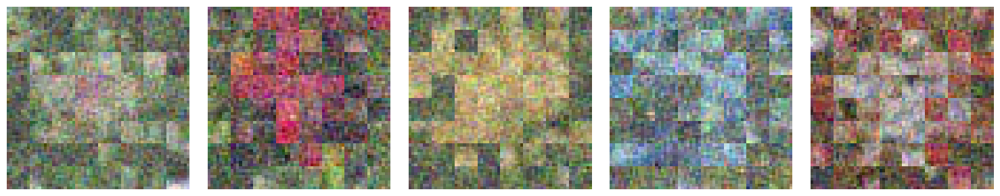

  0%|          | 0/5797 [00:00<?, ?it/s]

Epoch [  9/10] finished. Train MSE: 0.7306 | 

  0%|          | 0/1449 [00:00<?, ?it/s]

Test MSE: 0.7322



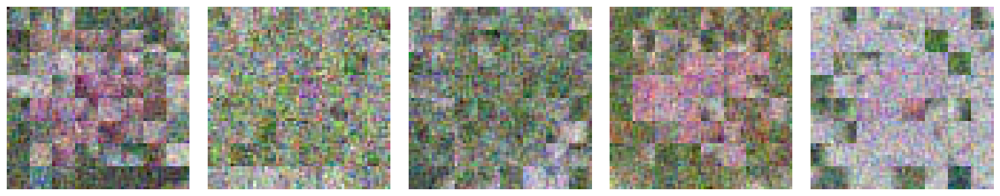

  0%|          | 0/5797 [00:00<?, ?it/s]

Epoch [ 10/10] finished. Train MSE: 0.7283 | 

  0%|          | 0/1449 [00:00<?, ?it/s]

Test MSE: 0.7287



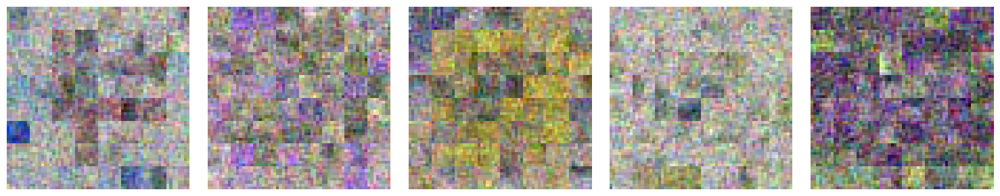

Training completed


In [ ]:
LR = 5e-4
VAL_EPOCHS = 1
EPOCHS = 10

test_loss, train_loss = train(n_epochs=EPOCHS, LR=LR, val_steps=VAL_EPOCHS)

<Axes: >

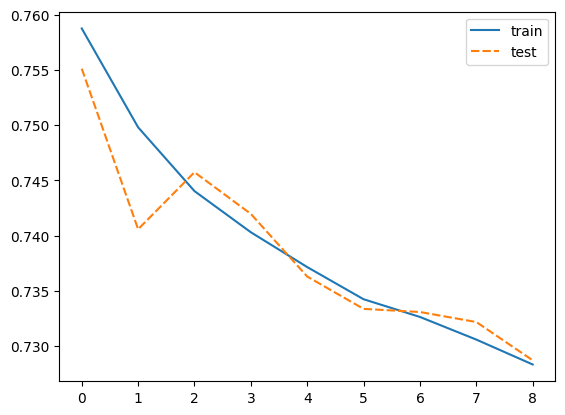

In [ ]:
sns.lineplot(data={'train': train_loss[1:], 'test': test_loss[1:]})
# plt.yscale('log')
# plt.show()

In [ ]:
def train_distill(n_epochs=10, LR=1e-4, save_dir='./models/', val_steps=1, img_show_steps=1):
    criterion = nn.MSELoss()
    optimizer = torch.optim.AdamW(model.parameters(), lr=LR)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=n_epochs, eta_min=0.00005)

    model.train()

    teacher_state_dict = torch.load('model.pth')
    teacher = DiT(img_size=WIDTH, patch_size=8, depth=16, hidden_dim=256, num_heads=8, in_channels=N_CHANNELS).to(device)
    teacher.load_state_dict(teacher_state_dict)

    val_losses = []
    train_losses = []

    for epoch in range(n_epochs):
        train_loss = 0
        for img in tqdm(train_loader, leave=False):
            img = img.to(device)
            noisy_img, t = add_noise_batch(img)
            noisy_img = noisy_img.to(device)
            t = t.to(device)

            predicted_noise = model(noisy_img, t)
            with torch.no_grad():
                teacher_noise = teacher(noisy_img, t)
            loss = criterion(teacher_noise, predicted_noise)
            train_loss += loss.item()

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

        train_loss /= train_loader.__len__()
        train_losses.append(train_loss)

        print(f'Epoch [{epoch + 1:3}/{n_epochs}] finished. Train MSE: {train_loss:.4f}', end=' | ')
        if epoch % val_steps == 0:
            val_loss = validate(criterion)
            val_losses.append(val_loss)
            print(f'Test MSE: {val_loss:.4f}')
        print()

        if epoch % img_show_steps == 0:
            img = generate(n_images=5, n_steps=1)

    print('Training completed')
    return val_losses, train_losses

  0%|          | 0/5797 [00:00<?, ?it/s]

Epoch [  1/10] finished. Train MSE: 0.4102 | 

  0%|          | 0/1449 [00:00<?, ?it/s]

Test MSE: 0.7594



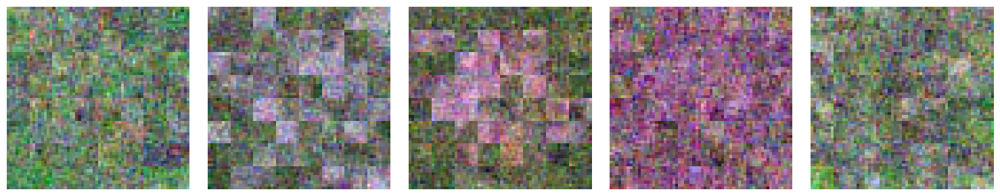

  0%|          | 0/5797 [00:00<?, ?it/s]

Epoch [  2/10] finished. Train MSE: 0.3356 | 

  0%|          | 0/1449 [00:00<?, ?it/s]

Test MSE: 0.7418



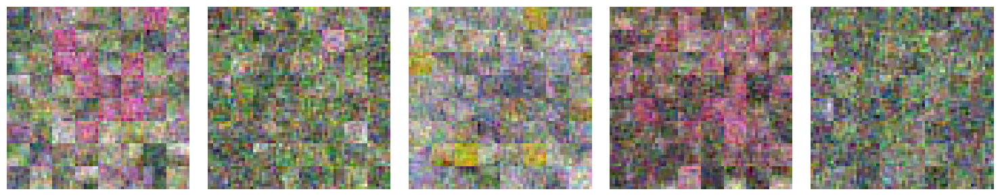

  0%|          | 0/5797 [00:00<?, ?it/s]

Epoch [  3/10] finished. Train MSE: 0.3273 | 

  0%|          | 0/1449 [00:00<?, ?it/s]

Test MSE: 0.7417



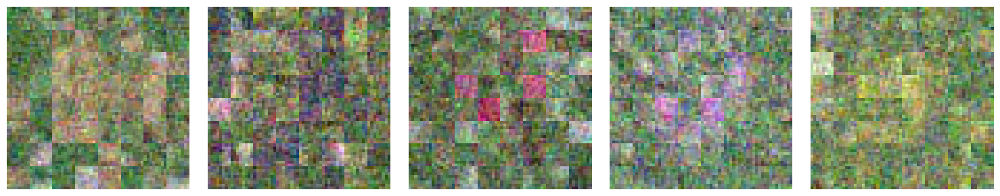

  0%|          | 0/5797 [00:00<?, ?it/s]

Epoch [  4/10] finished. Train MSE: 0.3227 | 

  0%|          | 0/1449 [00:00<?, ?it/s]

Test MSE: 0.7387



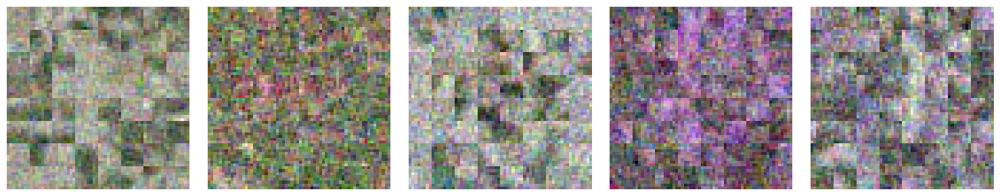

  0%|          | 0/5797 [00:00<?, ?it/s]

Epoch [  5/10] finished. Train MSE: 0.3204 | 

  0%|          | 0/1449 [00:00<?, ?it/s]

Test MSE: 0.7344



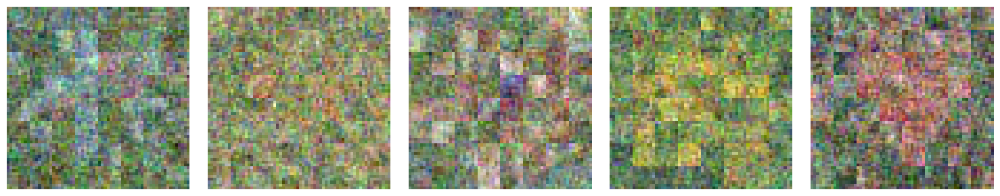

  0%|          | 0/5797 [00:00<?, ?it/s]

Epoch [  6/10] finished. Train MSE: 0.3184 | 

  0%|          | 0/1449 [00:00<?, ?it/s]

Test MSE: 0.7350



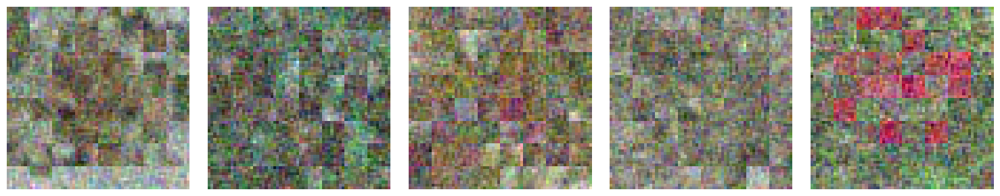

  0%|          | 0/5797 [00:00<?, ?it/s]

Epoch [  7/10] finished. Train MSE: 0.3171 | 

  0%|          | 0/1449 [00:00<?, ?it/s]

Test MSE: 0.7416



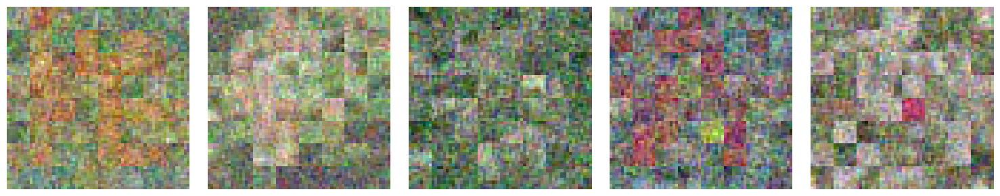

  0%|          | 0/5797 [00:00<?, ?it/s]

Epoch [  8/10] finished. Train MSE: 0.3138 | 

  0%|          | 0/1449 [00:00<?, ?it/s]

Test MSE: 0.7323



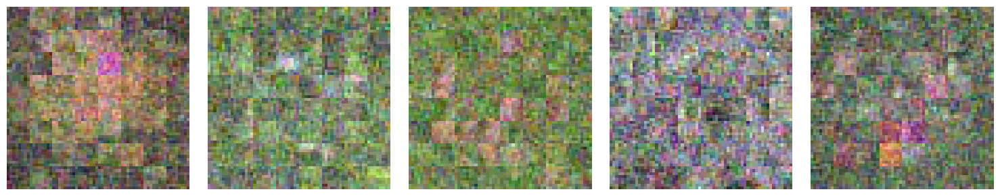

  0%|          | 0/5797 [00:00<?, ?it/s]

Epoch [  9/10] finished. Train MSE: 0.3125 | 

  0%|          | 0/1449 [00:00<?, ?it/s]

Test MSE: 0.7293



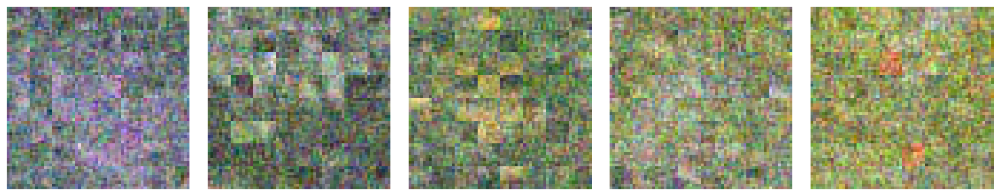

  0%|          | 0/5797 [00:00<?, ?it/s]

Epoch [ 10/10] finished. Train MSE: 0.3114 | 

  0%|          | 0/1449 [00:00<?, ?it/s]

Test MSE: 0.7274



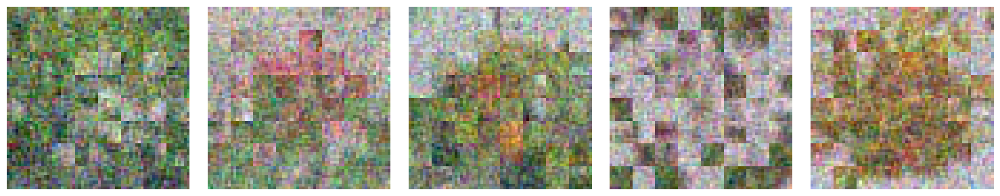

Training completed


In [ ]:
LR = 5e-4
VAL_EPOCHS = 1
EPOCHS = 10

test_loss, train_loss = train_distill(n_epochs=EPOCHS, LR=LR, val_steps=VAL_EPOCHS)

<Axes: >

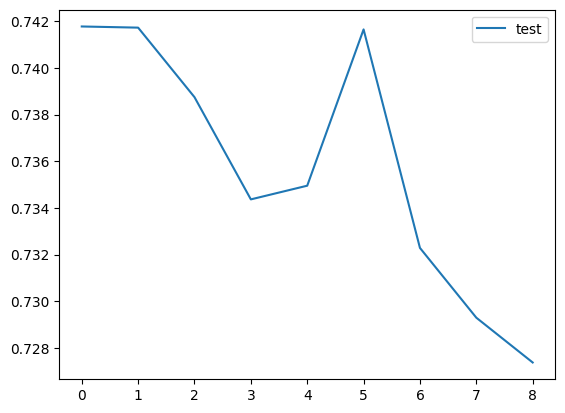

In [ ]:
sns.lineplot(data={'test': test_loss[1:]})
# plt.yscale('log')
# plt.show()

In [ ]:
def train_rectified(n_epochs=10, LR=1e-4, save_dir='./models/', val_steps=1, img_show_steps=1):
    criterion = nn.MSELoss()
    optimizer = torch.optim.AdamW(model.parameters(), lr=LR)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=n_epochs, eta_min=0.00005)

    model.train()

    teacher_state_dict = torch.load('model.pth')
    teacher = DiT(img_size=WIDTH, patch_size=8, depth=16, hidden_dim=256, num_heads=8, in_channels=N_CHANNELS).to(device)
    teacher.load_state_dict(teacher_state_dict)

    val_losses = []
    train_losses = []

    for epoch in range(n_epochs):
        train_loss = 0
        epoch_len = 100
        for img in tqdm(range(epoch_len), leave=False):
            n_images = BATCH_SIZE
            noise = torch.randn((n_images, N_CHANNELS, WIDTH, WIDTH), device=device).float()
            t = torch.rand(n_images, device=device).float()
            true_img = generation_step(noise, 0, 1, teacher)
            noisy_img = t.view(-1, 1, 1, 1) * true_img + (1 - t).view(-1, 1, 1, 1) * noise
            noisy_img = noisy_img.float()

            predicted_noise = model(noisy_img, t)
            loss = criterion((true_img - noise).float(), predicted_noise.float())
            train_loss += loss.item()

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

        train_loss /= epoch_len
        train_losses.append(train_loss)

        print(f'Epoch [{epoch + 1:3}/{n_epochs}] finished. Train MSE: {train_loss:.4f}', end=' | ')
        if epoch % val_steps == 0:
            val_loss = validate(criterion)
            val_losses.append(val_loss)
            print(f'Test MSE: {val_loss:.4f}')
        print()

        if epoch % img_show_steps == 0:
            img = generate(n_images=5, n_steps=1)

    print('Training completed')
    return val_losses, train_losses

  0%|          | 0/100 [00:00<?, ?it/s]

Epoch [  1/10] finished. Train MSE: 0.5537 | 

  0%|          | 0/1449 [00:00<?, ?it/s]

Test MSE: 0.9732



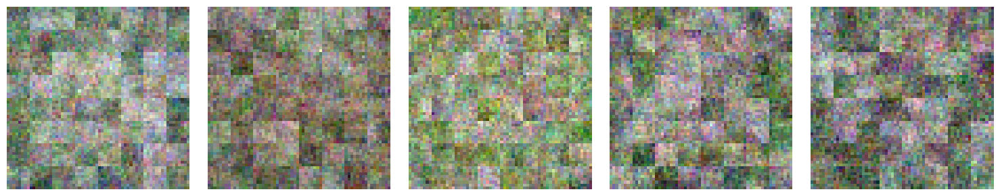

  0%|          | 0/100 [00:00<?, ?it/s]

Epoch [  2/10] finished. Train MSE: 0.4009 | 

  0%|          | 0/1449 [00:00<?, ?it/s]

Test MSE: 0.9249



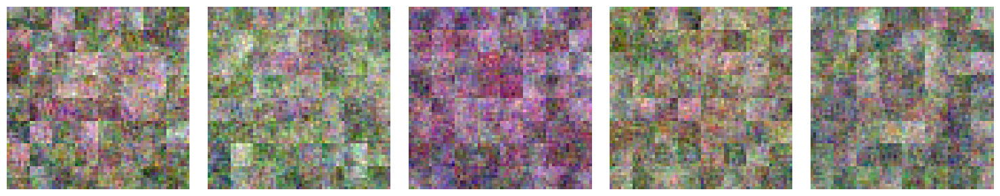

  0%|          | 0/100 [00:00<?, ?it/s]

Epoch [  3/10] finished. Train MSE: 0.3645 | 

  0%|          | 0/1449 [00:00<?, ?it/s]

Test MSE: 0.9063



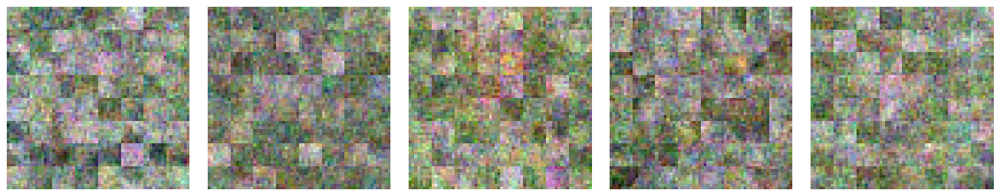

  0%|          | 0/100 [00:00<?, ?it/s]

Epoch [  4/10] finished. Train MSE: 0.3512 | 

  0%|          | 0/1449 [00:00<?, ?it/s]

Test MSE: 0.8929



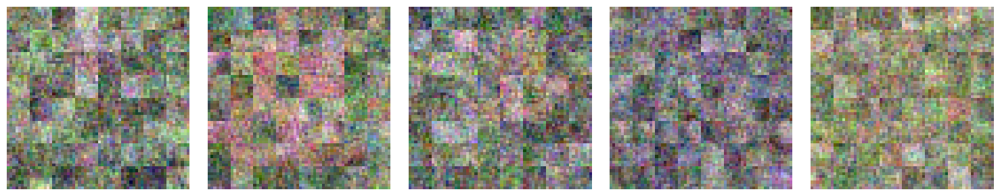

  0%|          | 0/100 [00:00<?, ?it/s]

Epoch [  5/10] finished. Train MSE: 0.3369 | 

  0%|          | 0/1449 [00:00<?, ?it/s]

Test MSE: 0.8814



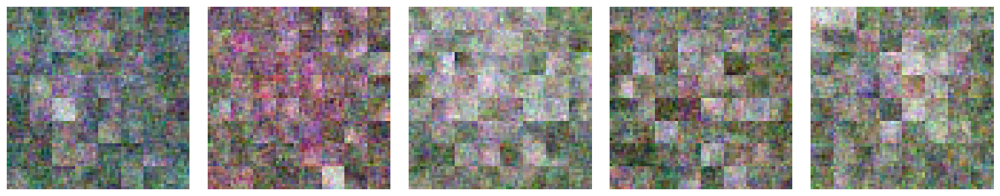

  0%|          | 0/100 [00:00<?, ?it/s]

Epoch [  6/10] finished. Train MSE: 0.3260 | 

  0%|          | 0/1449 [00:00<?, ?it/s]

Test MSE: 0.8822



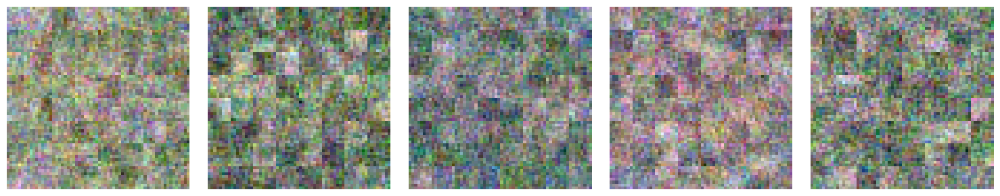

  0%|          | 0/100 [00:00<?, ?it/s]

Epoch [  7/10] finished. Train MSE: 0.3102 | 

  0%|          | 0/1449 [00:00<?, ?it/s]

Test MSE: 0.8623



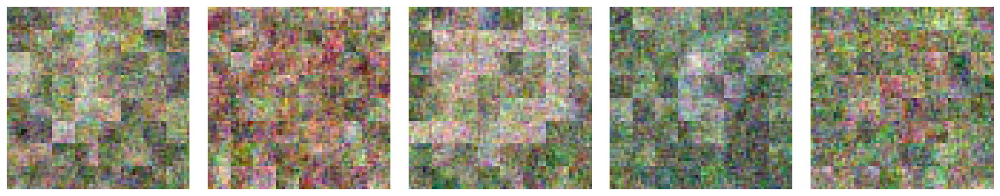

  0%|          | 0/100 [00:00<?, ?it/s]

Epoch [  8/10] finished. Train MSE: 0.3034 | 

  0%|          | 0/1449 [00:00<?, ?it/s]

Test MSE: 0.8482



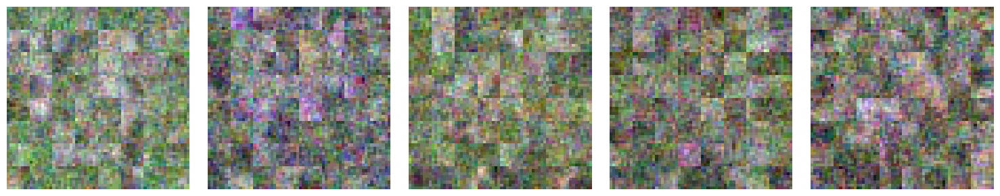

  0%|          | 0/100 [00:00<?, ?it/s]

Epoch [  9/10] finished. Train MSE: 0.3063 | 

  0%|          | 0/1449 [00:00<?, ?it/s]

Test MSE: 0.8508



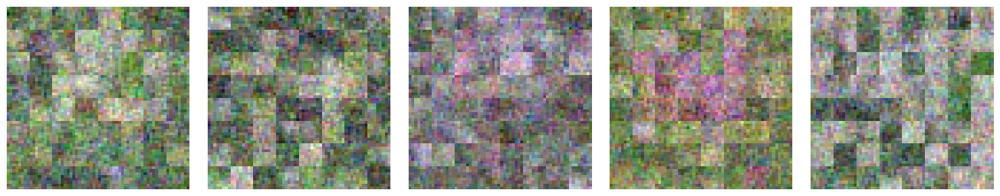

  0%|          | 0/100 [00:00<?, ?it/s]

Epoch [ 10/10] finished. Train MSE: 0.2992 | 

  0%|          | 0/1449 [00:00<?, ?it/s]

Test MSE: 0.8408



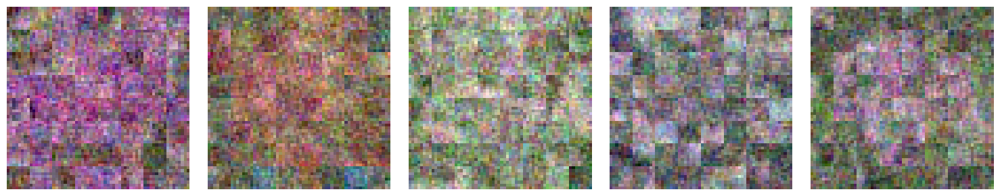

Training completed


In [ ]:
LR = 1e-3
VAL_EPOCHS = 1
EPOCHS = 10

test_loss, train_loss = train_rectified(n_epochs=EPOCHS, LR=LR, val_steps=VAL_EPOCHS)

<Axes: >

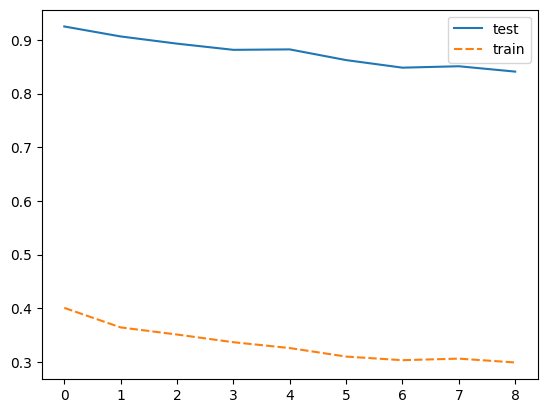

In [ ]:
sns.lineplot(data={'test': test_loss[1:], 'train':train_loss[1:]})
# plt.yscale('log')
# plt.show()

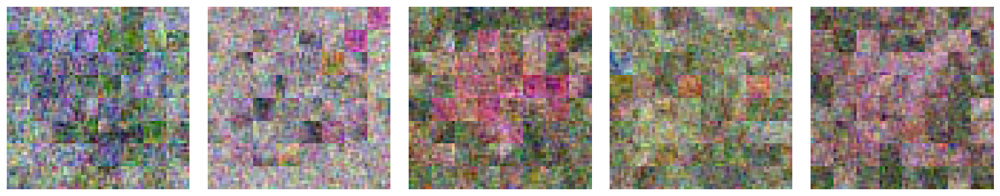

In [ ]:
img = generate(n_images=5, n_steps=1)

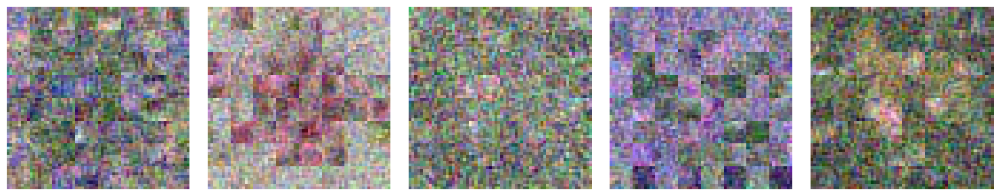

In [ ]:
img = generate(n_images=5, n_steps=10)

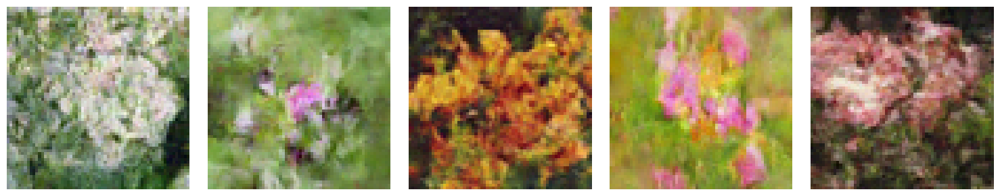

In [ ]:
img = generate(n_images=5, n_steps=30)

In [ ]:
img = generate(n_images=5, n_steps=60)

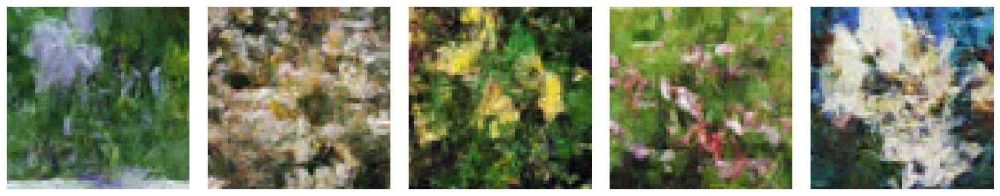

In [ ]:
img = generate(n_images=5, n_steps=100)

In [ ]:
torch.save(model.state_dict(), '/content/model.pth')

In [ ]:
img = generate(n_images=5, n_steps=150)

In [ ]:
img = generate(n_images=5, n_steps=200)

In [ ]:
import matplotlib.pyplot as plt
from IPython.display import display, clear_output
import time

@torch.no_grad()
def generate_with_animation(n_images, n_steps=MAX_STEPS, frame_rate=10):
    """
    Генерирует изображения с анимацией процесса в реальном времени.
    """
    img = torch.randn((n_images, N_CHANNELS, WIDTH, WIDTH), device=device)
    model.eval()

    # Вычисляем интервал между кадрами
    frame_interval = 1.0 / frame_rate

    for step in range(n_steps):
        # Делаем шаг генерации
        img = generation_step(img, step, n_steps)

        # Очищаем предыдущий вывод (для Jupyter)
        clear_output(wait=True)

        # Создаем новую фигуру
        fig, axes = plt.subplots(1, n_images, figsize=(4 * n_images, 4))
        if n_images == 1:
            axes = [axes]

        # Отображаем каждое изображение
        for i, ax in enumerate(axes):
            ax.set_axis_off()
            ax.set_title(f'Image {i+1} (Step {step+1}/{n_steps})')

            # Денормализуем и преобразуем для отображения
            img_display = img[i].cpu() * torch.tensor(STD).view(3, 1, 1) + torch.tensor(MEAN).view(3, 1, 1)
            img_display = img_display.permute(1, 2, 0).clamp(0, 1).numpy()
            ax.imshow(img_display)

        plt.tight_layout()
        plt.show()

        # Контролируем частоту кадров
        time.sleep(frame_interval)

    model.train()
    return img

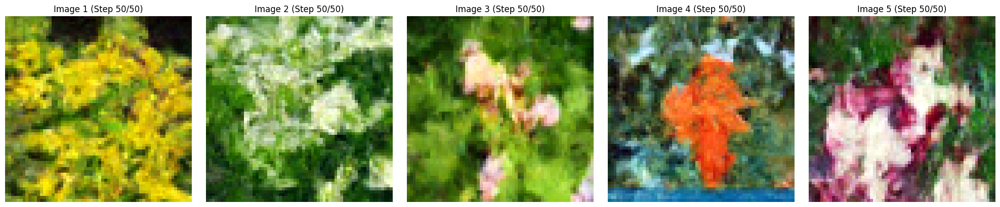

In [ ]:
img = generate_with_animation(n_images=5, n_steps=50, frame_rate=1000)

# Upscaling

In [ ]:
class Flower104(Dataset):
    def __init__(self, split='train', transform=None, transform_big=None):
        self.img_dir = img_dir + '/' + split
        image_paths = [list(map(lambda name: class_name + '/' + name, os.listdir(self.img_dir + '/' + class_name))) for class_name in os.listdir(self.img_dir)]
        image_paths = sum(image_paths, [])
        self.image_paths = image_paths
        self.transform = transform
        self.transform_big = transform_big

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):
        img_path = os.path.join(self.img_dir, self.image_paths[idx])
        img = Image.open(img_path).convert('RGB')
        return self.transform(img), self.transform_big(img)

In [ ]:
from torchvision.transforms import v2 as v2

BIG_WIDTH = 128

MEAN = [0.4475, 0.4168, 0.2963]
STD = [0.2791, 0.2415, 0.2653]

transform = transforms.Compose([
    transforms.Resize((WIDTH, WIDTH)),
    v2.JPEG((10, 50)),
    transforms.ToTensor(),
    # v2.GaussianBlur(kernel_size=3, sigma=0.7),
    # v2.GaussianNoise(sigma=.03),
    transforms.Normalize(MEAN, STD),
])

transform_big = transforms.Compose([
    transforms.Resize((BIG_WIDTH, BIG_WIDTH)),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

# train_ = Flower104(split='train', transform=transform)
# test_ = Flower104(split='val', transform=transform)

dataset = Flower104(split='Flowers299', transform=transform, transform_big=transform_big)

train_, test_ = random_split(dataset, [0.8, 0.2])

BATCH_SIZE = 64
N_CHANNELS = train_[0][0].size(0)
WIDTH = train_[0][0].size(1)

train_loader = DataLoader(train_, batch_size=BATCH_SIZE, shuffle=True, drop_last=True)
test_loader = DataLoader(test_, batch_size=BATCH_SIZE, shuffle=False, drop_last=True)

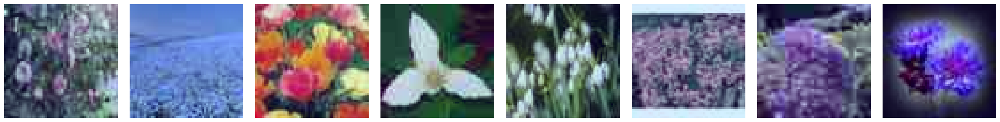

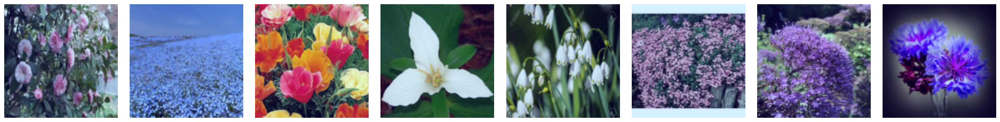

In [ ]:
small, big = next(iter(train_loader))
show_image(small[:8])
show_image(big[:8])

In [ ]:
import torch
import torch.nn as nn
from einops import rearrange


class PatchEmbedding(nn.Module):
    def __init__(self, in_channels=3, embed_dim=768, patch_size=16):
        super().__init__()
        self.patch_size = patch_size
        self.proj = nn.Conv2d(in_channels, embed_dim, kernel_size=patch_size, stride=patch_size)

    def forward(self, x):
        # x: [B, C, H, W]
        x = self.proj(x)  # [B, embed_dim, H/patch_size, W/patch_size]
        return x


class AttentionBlock(nn.Module):
    def __init__(self, embed_dim=768, num_heads=12, dropout=0.1):
        super().__init__()
        self.num_heads = num_heads
        self.head_dim = embed_dim // num_heads
        assert self.head_dim * num_heads == embed_dim, "embed_dim must be divisible by num_heads"

        self.norm1 = nn.LayerNorm(embed_dim)
        self.qkv = nn.Linear(embed_dim, embed_dim * 3)
        self.attn_dropout = nn.Dropout(dropout)
        self.proj = nn.Linear(embed_dim, embed_dim)
        self.proj_dropout = nn.Dropout(dropout)

        self.norm2 = nn.LayerNorm(embed_dim)
        self.mlp = nn.Sequential(
            nn.Linear(embed_dim, embed_dim * 4),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(embed_dim * 4, embed_dim),
            nn.Dropout(dropout)
        )

    def forward(self, x):
        # x: [B, N, embed_dim]
        B, N, C = x.shape

        # Self-attention with scaled dot product
        residual = x
        x = self.norm1(x)

        # Project to Q, K, V
        qkv = self.qkv(x)  # [B, N, 3*C]
        qkv = qkv.reshape(B, N, 3, self.num_heads, self.head_dim).permute(2, 0, 3, 1, 4)
        q, k, v = qkv.unbind(0)  # Each: [B, num_heads, N, head_dim]

        # Scaled dot product attention
        attn_output = torch.nn.functional.scaled_dot_product_attention(
            q, k, v,
            dropout_p=self.attn_dropout.p if self.training else 0.0
        )  # [B, num_heads, N, head_dim]

        # Reshape and project
        attn_output = attn_output.transpose(1, 2).reshape(B, N, C)  # [B, N, C]
        attn_output = self.proj(attn_output)
        attn_output = self.proj_dropout(attn_output)

        x = residual + attn_output

        # MLP
        residual = x
        x = self.norm2(x)
        x = self.mlp(x)
        x = residual + x

        return x


class ViTDelta(nn.Module):
    def __init__(self, in_channels=3, embed_dim=768, num_heads=12,
                 num_layers=6, patch_size=16, image_size=None):
        super().__init__()
        self.patch_size = patch_size
        self.embed_dim = embed_dim

        self.patch_embed = PatchEmbedding(in_channels, embed_dim, patch_size)

        # Position embeddings (learnable)
        if image_size is not None:
            num_patches = (image_size // patch_size) ** 2
            self.pos_embed = nn.Parameter(torch.zeros(1, num_patches, embed_dim))
        else:
            self.pos_embed = None

        self.transformer_blocks = nn.ModuleList([
            AttentionBlock(embed_dim, num_heads) for _ in range(num_layers)
        ])

        self.norm = nn.LayerNorm(embed_dim)

        # Project back to pixel space
        self.decoder = nn.Sequential(
            nn.Linear(embed_dim, embed_dim * 4),
            nn.GELU(),
            nn.Linear(embed_dim * 4, patch_size * patch_size * in_channels)
        )

        # Initialize positional embeddings
        if self.pos_embed is not None:
            nn.init.trunc_normal_(self.pos_embed, std=0.02)

    def forward(self, x):
        # x: [B, C, H, W]
        B, C, H, W = x.shape

        # Patch embedding
        patches = self.patch_embed(x)  # [B, embed_dim, H_p, W_p]
        B, E, H_p, W_p = patches.shape

        # Flatten to sequence
        x_seq = rearrange(patches, 'b e h w -> b (h w) e')  # [B, N, embed_dim]

        # Add positional embeddings
        if self.pos_embed is not None:
            x_seq = x_seq + self.pos_embed
        else:
            # Create positional embeddings dynamically based on sequence length
            seq_len = x_seq.shape[1]
            pos_embed = torch.zeros(1, seq_len, self.embed_dim, device=x.device, dtype=x.dtype)
            # Sinusoidal positional encoding
            position = torch.arange(seq_len, device=x.device).unsqueeze(1).float()
            div_term = torch.exp(torch.arange(0, self.embed_dim, 2, device=x.device).float() *
                                -(torch.log(torch.tensor(10000.0)) / self.embed_dim))
            pos_embed[:, :, 0::2] = torch.sin(position * div_term)
            pos_embed[:, :, 1::2] = torch.cos(position * div_term)
            x_seq = x_seq + pos_embed[:, :seq_len, :]

        # Transformer blocks
        for block in self.transformer_blocks:
            x_seq = block(x_seq)

        x_seq = self.norm(x_seq)

        # Decode back to patches
        decoded = self.decoder(x_seq)  # [B, N, patch_size*patch_size*C]

        # Reshape to image
        decoded = rearrange(decoded, 'b (h w) (p1 p2 c) -> b c (h p1) (w p2)',
                           h=H_p, w=W_p, p1=self.patch_size, p2=self.patch_size, c=C)

        return decoded


class UpscalerWithViT(nn.Module):
    def __init__(self, init_width=WIDTH, out_width=BIG_WIDTH,
                 vit_embed_dim=768, vit_num_heads=12, vit_num_layers=6,
                 vit_patch_size=16):
        super().__init__()
        self.up = nn.Upsample(scale_factor=2, mode='nearest')

        # Calculate input size for ViT after upsampling
        upsampled_size = init_width * 2
        self.vit_delta = ViTDelta(
            in_channels=3,
            embed_dim=vit_embed_dim,
            num_heads=vit_num_heads,
            num_layers=vit_num_layers,
            patch_size=vit_patch_size,
            image_size=upsampled_size
        )

    def forward(self, x):
        x = self.up(x)
        delta = self.vit_delta(x)
        return x + delta

In [ ]:
model = UpscalerWithViT(
    init_width=WIDTH,
    out_width=BIG_WIDTH,
    vit_embed_dim=768,
    vit_num_heads=6,
    vit_num_layers=4,
    vit_patch_size=16,
).to(device)

summary(model, input_size=(N_CHANNELS, WIDTH, WIDTH), batch_size=BATCH_SIZE)

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
          Upsample-1          [64, 3, 128, 128]               0
            Conv2d-2            [64, 768, 8, 8]         590,592
    PatchEmbedding-3            [64, 768, 8, 8]               0
         LayerNorm-4              [64, 64, 768]           1,536
            Linear-5             [64, 64, 2304]       1,771,776
            Linear-6              [64, 64, 768]         590,592
           Dropout-7              [64, 64, 768]               0
         LayerNorm-8              [64, 64, 768]           1,536
            Linear-9             [64, 64, 3072]       2,362,368
             GELU-10             [64, 64, 3072]               0
          Dropout-11             [64, 64, 3072]               0
           Linear-12              [64, 64, 768]       2,360,064
          Dropout-13              [64, 64, 768]               0
   AttentionBlock-14              [64, 

In [ ]:
teacher_state_dict = torch.load('model.pth')
teacher = DiT(img_size=WIDTH, patch_size=8, depth=16, hidden_dim=256, num_heads=8, in_channels=N_CHANNELS).to(device)
teacher.load_state_dict(teacher_state_dict)

<All keys matched successfully>

In [ ]:
def delta_image(image):
  return torch.stack((image[:, :, 1:, :] - image[:, :, :-1, :],
                      (image[:, :, :, 1:] - image[:, :, :, :-1]).reshape(-1, 3, BIG_WIDTH - 1, BIG_WIDTH)))

In [ ]:
def train_big(n_epochs=10, LR=1e-4, save_dir='./models/', val_steps=1, img_show_steps=1):
    criterion = nn.MSELoss()
    optimizer = torch.optim.AdamW(model.parameters(), lr=LR)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=n_epochs, eta_min=0.00005)

    model.train()

    val_losses = []
    train_losses = []

    for epoch in range(n_epochs):
        train_loss = 0
        for i, (small, big) in enumerate(tqdm(train_loader, leave=False)):
            small = small.to(device)
            big = big.to(device)

            predicted_img = model(small)
            delta_img_loss = criterion(delta_image(predicted_img), delta_image(big))
            loss = criterion(predicted_img, big) + delta_img_loss * .3
            train_loss += loss.item()

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            if i % 100 == 20:
                print(f'Iteration {i}:{len(train_loader)} | Loss: {train_loss / i:.4f}')

        train_loss /= len(train_loader)
        train_losses.append(train_loss)

        print(f'Epoch [{epoch + 1:3}/{n_epochs}] finished. Train MSE: {train_loss:.4f}', end=' | ')
        # if epoch % val_steps == 0:
        #     val_loss = validate(criterion)
        #     val_losses.append(val_loss)
        #     print(f'Test MSE: {val_loss:.4f}')
        # print()

        if epoch % img_show_steps == 0:
            img = generate(n_images=5, n_steps=1, cur_model=teacher)
            big_img = model(img.float())
            show_image(big_img.detach().cpu() * torch.tensor(STD).view(1, -1, 1, 1) + torch.tensor(MEAN).view(1, -1, 1, 1))


    print('Training completed')
    return val_losses, train_losses

  0%|          | 0/1449 [00:00<?, ?it/s]

Iteration 20:1449 | Loss: 0.1505
Iteration 120:1449 | Loss: 0.1301
Iteration 220:1449 | Loss: 0.1250
Iteration 320:1449 | Loss: 0.1219
Iteration 420:1449 | Loss: 0.1201
Iteration 520:1449 | Loss: 0.1191
Iteration 620:1449 | Loss: 0.1180
Iteration 720:1449 | Loss: 0.1171
Iteration 820:1449 | Loss: 0.1162
Iteration 920:1449 | Loss: 0.1155
Iteration 1020:1449 | Loss: 0.1148
Iteration 1120:1449 | Loss: 0.1141
Iteration 1220:1449 | Loss: 0.1134
Iteration 1320:1449 | Loss: 0.1128
Iteration 1420:1449 | Loss: 0.1123
Epoch [  1/10] finished. Train MSE: 0.1121 | 

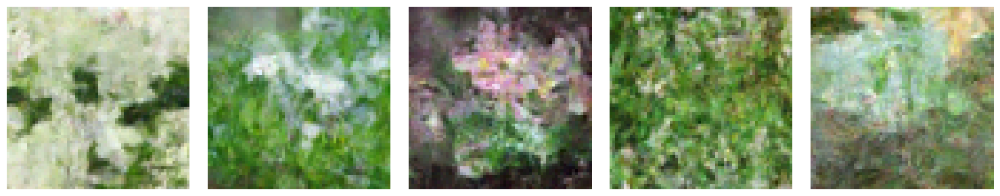

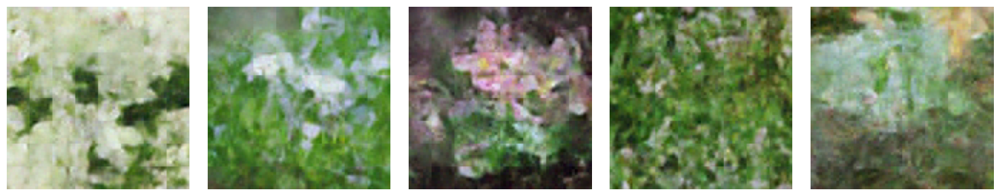

  0%|          | 0/1449 [00:00<?, ?it/s]

Iteration 20:1449 | Loss: 0.1119
Iteration 120:1449 | Loss: 0.1063
Iteration 220:1449 | Loss: 0.1054
Iteration 320:1449 | Loss: 0.1051
Iteration 420:1449 | Loss: 0.1049
Iteration 520:1449 | Loss: 0.1046
Iteration 620:1449 | Loss: 0.1044
Iteration 720:1449 | Loss: 0.1040
Iteration 820:1449 | Loss: 0.1039
Iteration 920:1449 | Loss: 0.1038
Iteration 1020:1449 | Loss: 0.1037
Iteration 1120:1449 | Loss: 0.1034
Iteration 1220:1449 | Loss: 0.1033
Iteration 1320:1449 | Loss: 0.1032
Iteration 1420:1449 | Loss: 0.1031
Epoch [  2/10] finished. Train MSE: 0.1029 | 

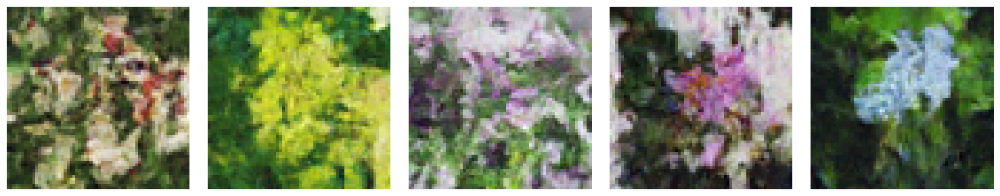

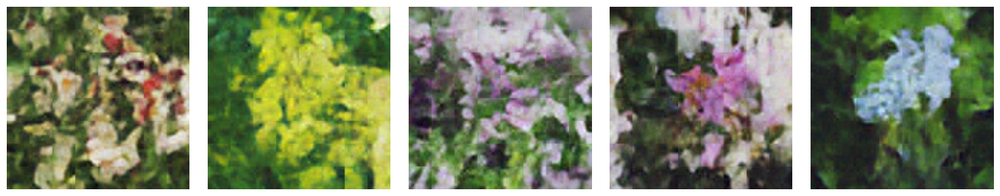

  0%|          | 0/1449 [00:00<?, ?it/s]

Iteration 20:1449 | Loss: 0.1057
Iteration 120:1449 | Loss: 0.1023
Iteration 220:1449 | Loss: 0.1011
Iteration 320:1449 | Loss: 0.1004
Iteration 420:1449 | Loss: 0.1001
Iteration 520:1449 | Loss: 0.0998
Iteration 620:1449 | Loss: 0.0997
Iteration 720:1449 | Loss: 0.0993
Iteration 820:1449 | Loss: 0.0992
Iteration 920:1449 | Loss: 0.0990
Iteration 1020:1449 | Loss: 0.0989
Iteration 1120:1449 | Loss: 0.0988
Iteration 1220:1449 | Loss: 0.0987
Iteration 1320:1449 | Loss: 0.0985
Iteration 1420:1449 | Loss: 0.0984
Epoch [  3/10] finished. Train MSE: 0.0983 | 

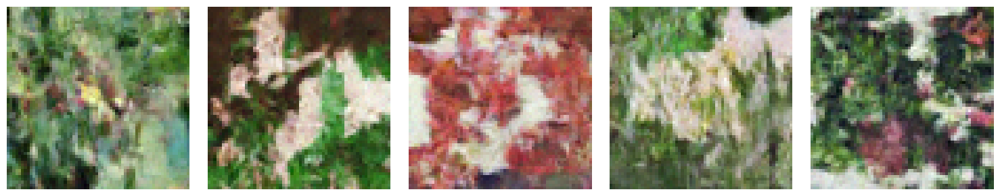

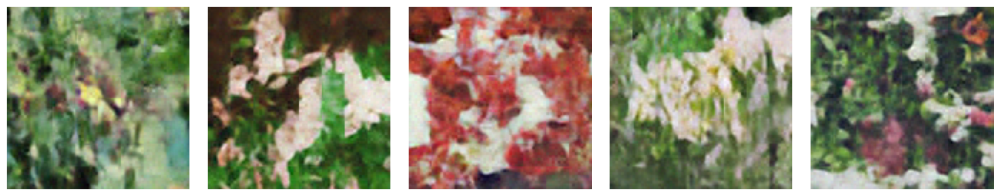

  0%|          | 0/1449 [00:00<?, ?it/s]

Iteration 20:1449 | Loss: 0.1000
Iteration 120:1449 | Loss: 0.0978
Iteration 220:1449 | Loss: 0.0972
Iteration 320:1449 | Loss: 0.0965
Iteration 420:1449 | Loss: 0.0968
Iteration 520:1449 | Loss: 0.0966
Iteration 620:1449 | Loss: 0.0967
Iteration 720:1449 | Loss: 0.0966
Iteration 820:1449 | Loss: 0.0966
Iteration 920:1449 | Loss: 0.0964
Iteration 1020:1449 | Loss: 0.0963
Iteration 1120:1449 | Loss: 0.0963
Iteration 1220:1449 | Loss: 0.0962
Iteration 1320:1449 | Loss: 0.0962
Iteration 1420:1449 | Loss: 0.0960
Epoch [  4/10] finished. Train MSE: 0.0960 | 

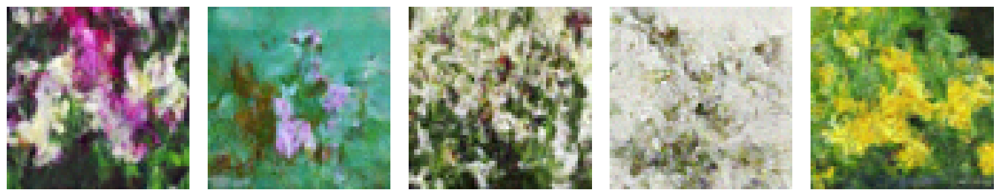

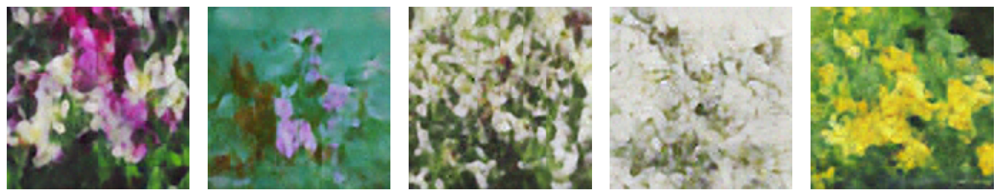

  0%|          | 0/1449 [00:00<?, ?it/s]

Iteration 20:1449 | Loss: 0.0971
Iteration 120:1449 | Loss: 0.0959
Iteration 220:1449 | Loss: 0.0954
Iteration 320:1449 | Loss: 0.0954
Iteration 420:1449 | Loss: 0.0955
Iteration 520:1449 | Loss: 0.0954
Iteration 620:1449 | Loss: 0.0952
Iteration 720:1449 | Loss: 0.0950
Iteration 820:1449 | Loss: 0.0950
Iteration 920:1449 | Loss: 0.0950
Iteration 1020:1449 | Loss: 0.0950
Iteration 1120:1449 | Loss: 0.0950
Iteration 1220:1449 | Loss: 0.0950
Iteration 1320:1449 | Loss: 0.0950
Iteration 1420:1449 | Loss: 0.0950
Epoch [  5/10] finished. Train MSE: 0.0949 | 

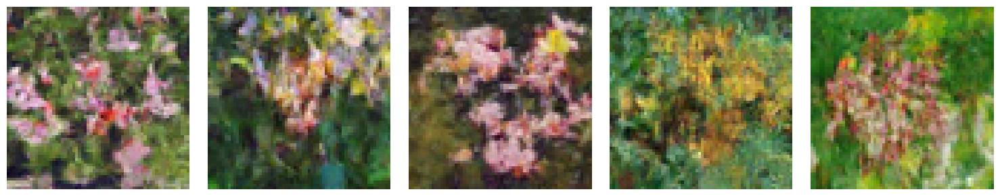

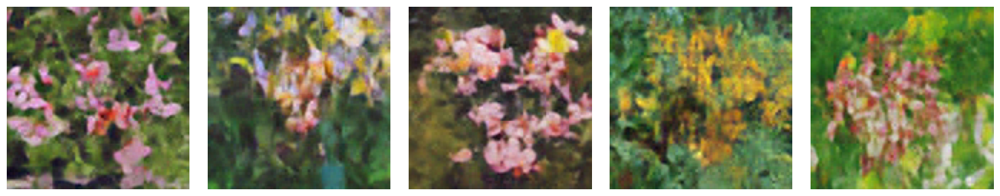

  0%|          | 0/1449 [00:00<?, ?it/s]

Iteration 20:1449 | Loss: 0.0986
Iteration 120:1449 | Loss: 0.0947
Iteration 220:1449 | Loss: 0.0945
Iteration 320:1449 | Loss: 0.0946
Iteration 420:1449 | Loss: 0.0946
Iteration 520:1449 | Loss: 0.0944
Iteration 620:1449 | Loss: 0.0944
Iteration 720:1449 | Loss: 0.0942
Iteration 820:1449 | Loss: 0.0942
Iteration 920:1449 | Loss: 0.0942
Iteration 1020:1449 | Loss: 0.0941
Iteration 1120:1449 | Loss: 0.0941
Iteration 1220:1449 | Loss: 0.0941
Iteration 1320:1449 | Loss: 0.0940
Iteration 1420:1449 | Loss: 0.0941
Epoch [  6/10] finished. Train MSE: 0.0940 | 

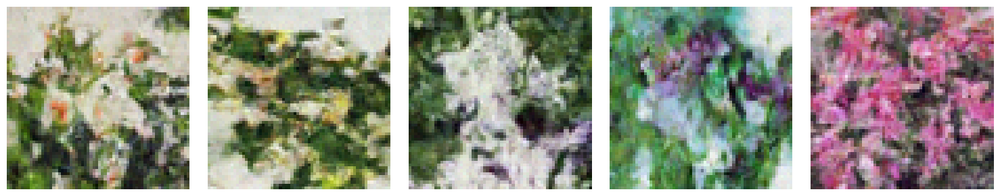

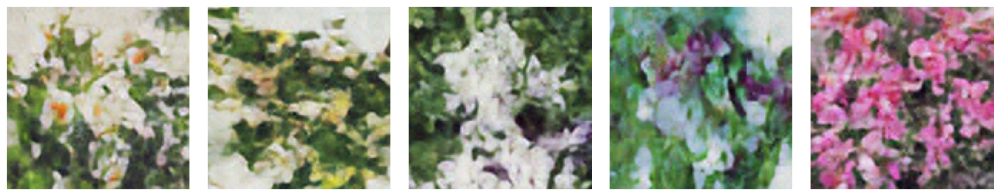

  0%|          | 0/1449 [00:00<?, ?it/s]

Iteration 20:1449 | Loss: 0.0973
Iteration 120:1449 | Loss: 0.0949
Iteration 220:1449 | Loss: 0.0946
Iteration 320:1449 | Loss: 0.0943
Iteration 420:1449 | Loss: 0.0940
Iteration 520:1449 | Loss: 0.0939
Iteration 620:1449 | Loss: 0.0938
Iteration 720:1449 | Loss: 0.0936
Iteration 820:1449 | Loss: 0.0937
Iteration 920:1449 | Loss: 0.0937
Iteration 1020:1449 | Loss: 0.0938
Iteration 1120:1449 | Loss: 0.0937
Iteration 1220:1449 | Loss: 0.0936
Iteration 1320:1449 | Loss: 0.0935
Iteration 1420:1449 | Loss: 0.0935
Epoch [  7/10] finished. Train MSE: 0.0934 | 

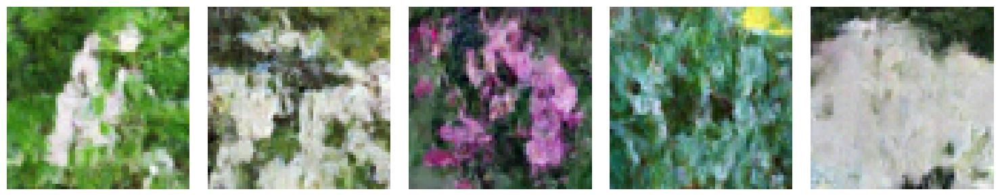

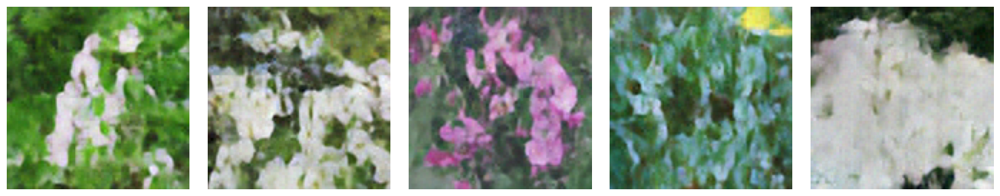

  0%|          | 0/1449 [00:00<?, ?it/s]

Iteration 20:1449 | Loss: 0.0985
Iteration 120:1449 | Loss: 0.0932
Iteration 220:1449 | Loss: 0.0933
Iteration 320:1449 | Loss: 0.0932
Iteration 420:1449 | Loss: 0.0932
Iteration 520:1449 | Loss: 0.0934
Iteration 620:1449 | Loss: 0.0931
Iteration 720:1449 | Loss: 0.0931
Iteration 820:1449 | Loss: 0.0931
Iteration 920:1449 | Loss: 0.0931
Iteration 1020:1449 | Loss: 0.0931
Iteration 1120:1449 | Loss: 0.0932
Iteration 1220:1449 | Loss: 0.0931
Iteration 1320:1449 | Loss: 0.0931
Iteration 1420:1449 | Loss: 0.0931
Epoch [  8/10] finished. Train MSE: 0.0930 | 

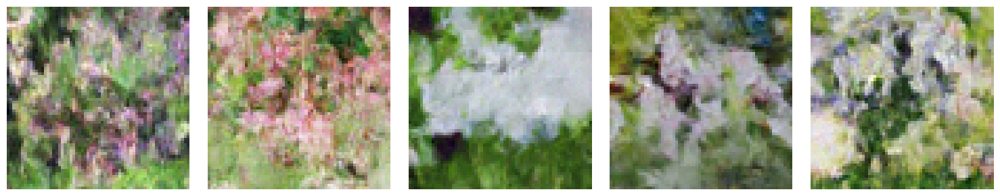

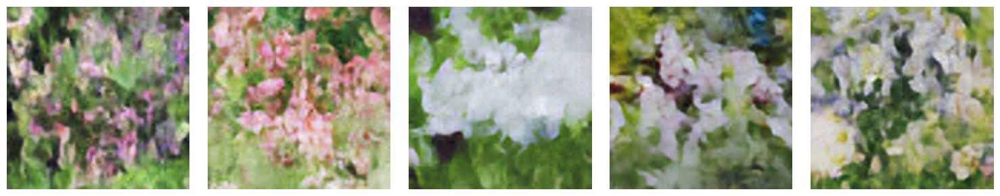

  0%|          | 0/1449 [00:00<?, ?it/s]

Iteration 20:1449 | Loss: 0.0978
Iteration 120:1449 | Loss: 0.0931
Iteration 220:1449 | Loss: 0.0928
Iteration 320:1449 | Loss: 0.0932
Iteration 420:1449 | Loss: 0.0932
Iteration 520:1449 | Loss: 0.0930
Iteration 620:1449 | Loss: 0.0930
Iteration 720:1449 | Loss: 0.0929
Iteration 820:1449 | Loss: 0.0927
Iteration 920:1449 | Loss: 0.0925
Iteration 1020:1449 | Loss: 0.0926
Iteration 1120:1449 | Loss: 0.0927
Iteration 1220:1449 | Loss: 0.0926
Iteration 1320:1449 | Loss: 0.0926
Iteration 1420:1449 | Loss: 0.0926
Epoch [  9/10] finished. Train MSE: 0.0925 | 

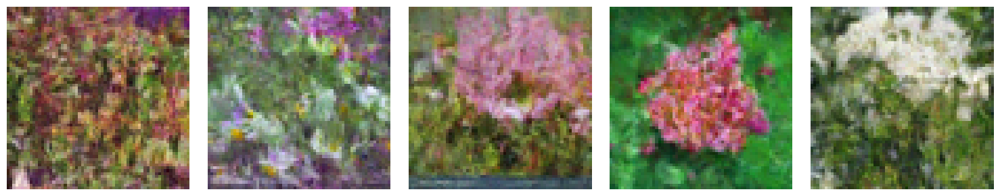

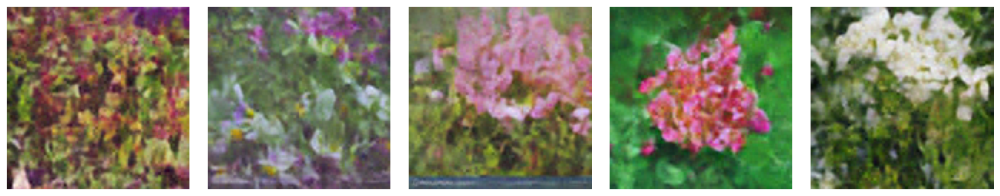

  0%|          | 0/1449 [00:00<?, ?it/s]

Iteration 20:1449 | Loss: 0.0949
Iteration 120:1449 | Loss: 0.0906
Iteration 220:1449 | Loss: 0.0911
Iteration 320:1449 | Loss: 0.0914
Iteration 420:1449 | Loss: 0.0918
Iteration 520:1449 | Loss: 0.0918
Iteration 620:1449 | Loss: 0.0920
Iteration 720:1449 | Loss: 0.0921
Iteration 820:1449 | Loss: 0.0921
Iteration 920:1449 | Loss: 0.0921
Iteration 1020:1449 | Loss: 0.0922
Iteration 1120:1449 | Loss: 0.0922
Iteration 1220:1449 | Loss: 0.0922
Iteration 1320:1449 | Loss: 0.0922
Iteration 1420:1449 | Loss: 0.0922
Epoch [ 10/10] finished. Train MSE: 0.0922 | 

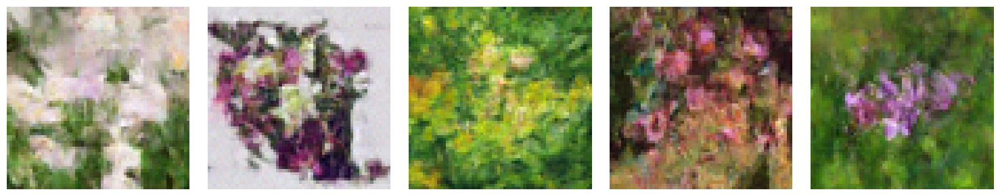

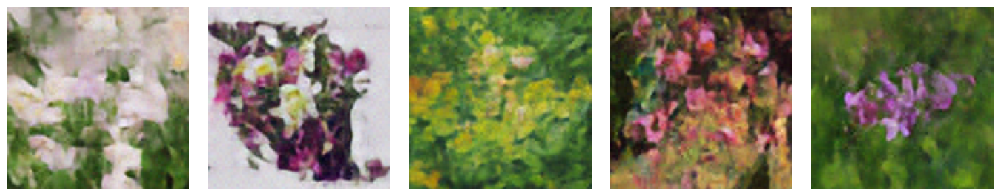

Training completed


([],
 [0.11214328690941701,
  0.10294882812793704,
  0.09829168096236149,
  0.09598495722269502,
  0.09491547693808873,
  0.09404039800969216,
  0.09336013829732781,
  0.09301488466555699,
  0.0924897995373148,
  0.0922135145778159])

In [ ]:
N_EPOCHS = 10
LR = 4e-4

train_big(N_EPOCHS, LR)

In [ ]:
def generate_big():
    img = generate(5, 100, cur_model=teacher, show=False)
    big_img = model(img.float())
    show_image(big_img)

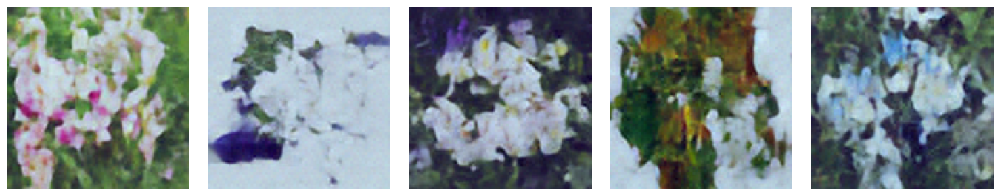

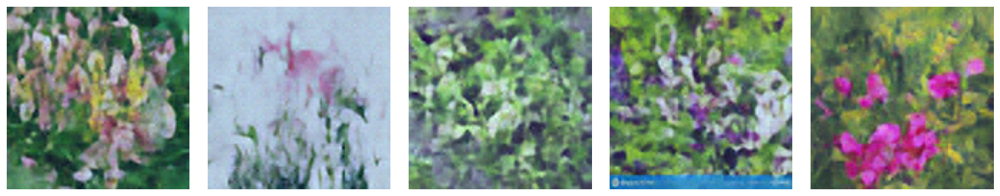

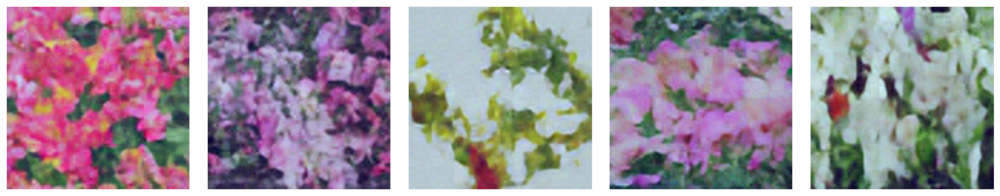

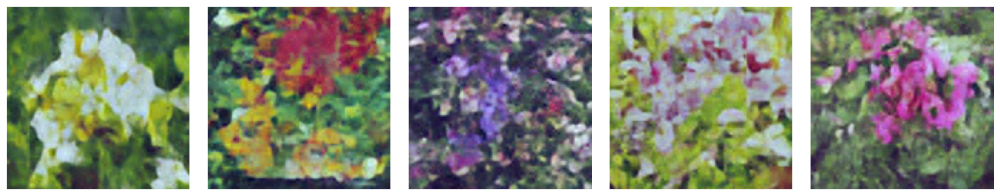

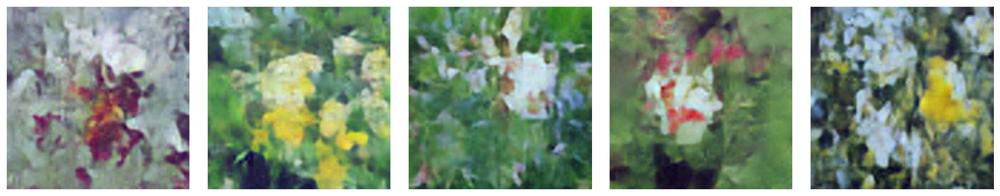

In [ ]:
generate_big()
generate_big()
generate_big()
generate_big()
generate_big()

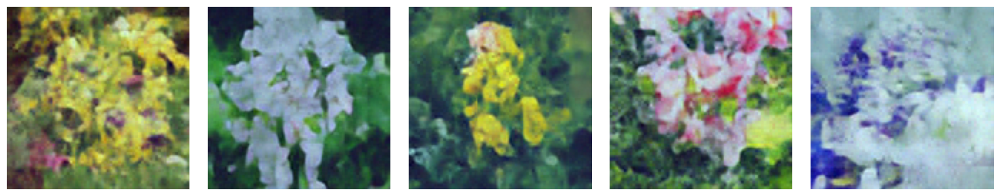

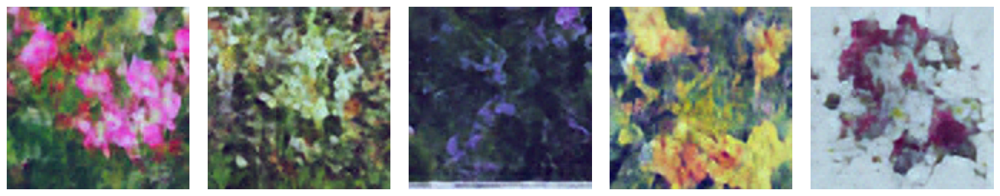

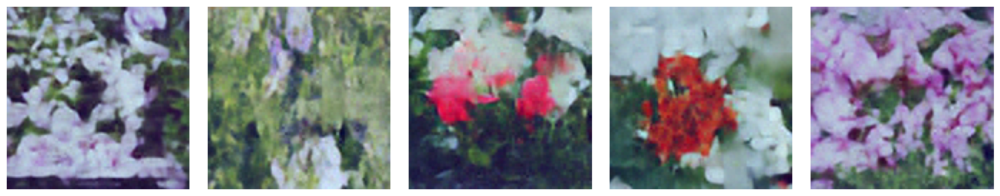

In [ ]:
generate_big()
generate_big()
generate_big()

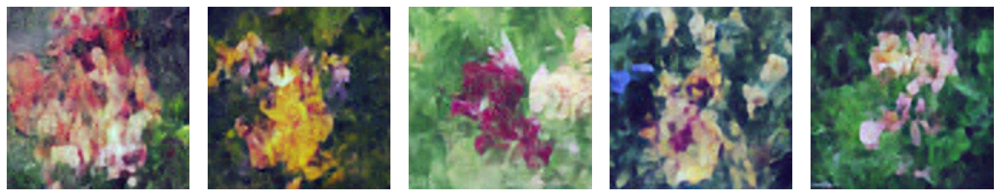

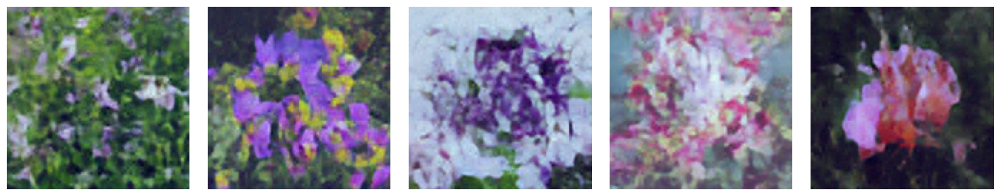

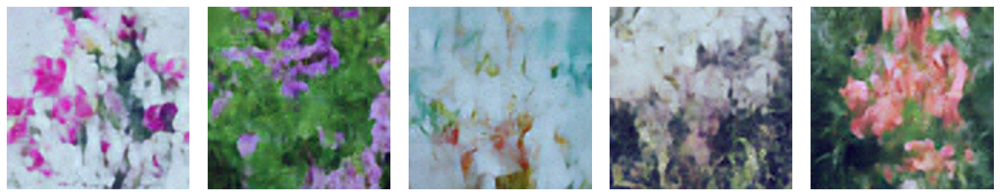

In [ ]:
generate_big()
generate_big()
generate_big()

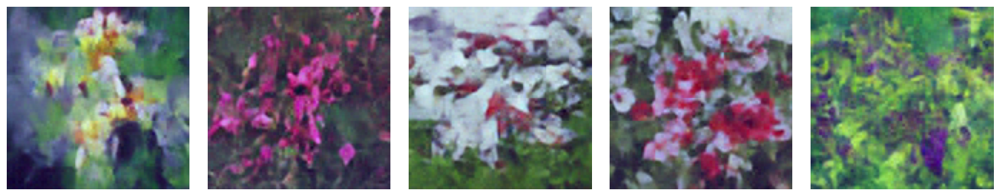

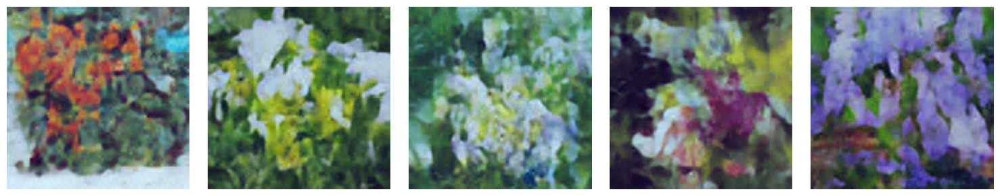

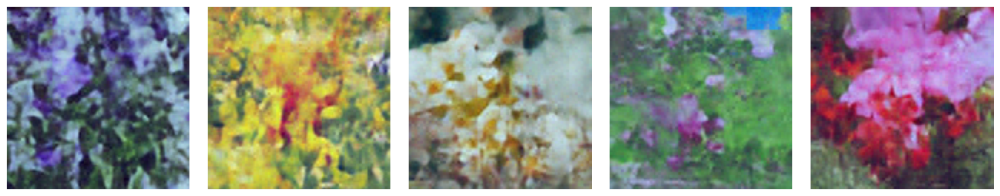

In [ ]:
generate_big()
generate_big()
generate_big()